# Taxi Demand Forecasting

## Business Objective

Sweet Lift Taxi aims to forecast the number of airport taxi orders for the next hour to support driver allocation during peak demand. Historical order data is aggregated into hourly observations, analyzed for trends and seasonality, and used to train regression models. The performance target is **test RMSE ≤ 48**.

**Target:** `num_orders` (hourly taxi orders).

**Approach:** chronological train/validation/test split, time-based feature engineering, model comparison, and evaluation on a held-out test set.

## 1. Data Preparation

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from statsmodels.tsa.seasonal import seasonal_decompose

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error

In [21]:
# Load historical taxi orders
data = pd.read_csv(
    '../data/taxi.csv',
    index_col=[0],
    parse_dates=[0]
)

print(data.head())
print(data.info())
print(data.shape)

                     num_orders
datetime                       
2018-03-01 00:00:00           9
2018-03-01 00:10:00          14
2018-03-01 00:20:00          28
2018-03-01 00:30:00          20
2018-03-01 00:40:00          32
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 26496 entries, 2018-03-01 00:00:00 to 2018-08-31 23:50:00
Data columns (total 1 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   num_orders  26496 non-null  int64
dtypes: int64(1)
memory usage: 414.0 KB
None
(26496, 1)


In [22]:
print('Valores ausentes:')
print(data.isna().sum())

print('\nDuplicatas:')
print(data.index.duplicated().sum())

print('\nOrdem cronológica:')
print(data.index.is_monotonic_increasing)

print('\nEstatísticas descritivas:')
print(data.describe())

Valores ausentes:
num_orders    0
dtype: int64

Duplicatas:
0

Ordem cronológica:
True

Estatísticas descritivas:
         num_orders
count  26496.000000
mean      14.070463
std        9.211330
min        0.000000
25%        8.000000
50%       13.000000
75%       19.000000
max      119.000000


In [23]:
# Aggregate orders into hourly intervals

data = data.resample('1h').sum()

print(data.head())
print()
print('Shape after resampling:', data.shape)
print()
print(data.describe())

                     num_orders
datetime                       
2018-03-01 00:00:00         124
2018-03-01 01:00:00          85
2018-03-01 02:00:00          71
2018-03-01 03:00:00          66
2018-03-01 04:00:00          43

Dimensões após reamostragem: (4416, 1)

        num_orders
count  4416.000000
mean     84.422781
std      45.023853
min       0.000000
25%      54.000000
50%      78.000000
75%     107.000000
max     462.000000


The original dataset contains 26,496 records. No missing values or duplicate timestamps were found. After hourly resampling, the dataset contains 4,416 observations, with an average of 84.42 orders per hour and values ranging from 0 to 462.

## 2. Exploratory Time Series Analysis

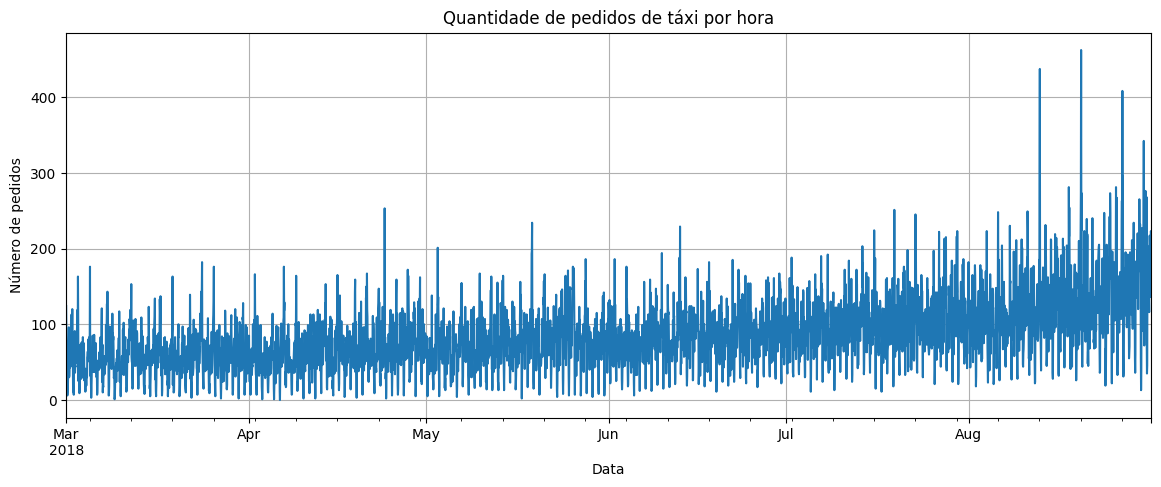

In [24]:
# Plot hourly taxi demand

plt.figure(figsize=(14, 5))

data['num_orders'].plot()

plt.title('Hourly taxi orders')
plt.xlabel('Date')
plt.ylabel('Number of orders')
plt.grid()
plt.show()

Taxi order volumes generally increase over the observed months, particularly in July and August. Repeated fluctuations and demand spikes suggest seasonality worth investigating.

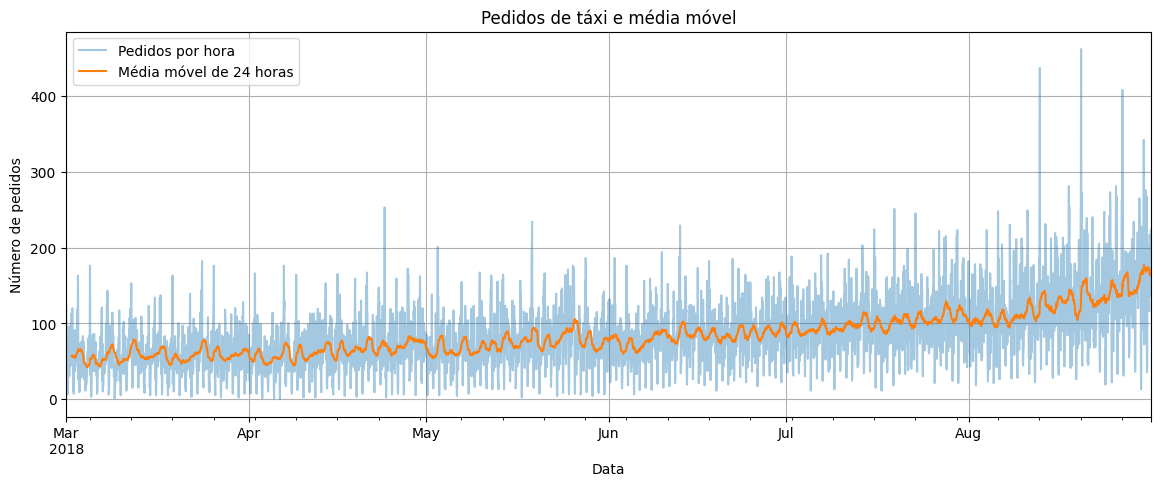

In [25]:
# Analyze the 24-hour rolling mean

data['rolling_mean'] = data['num_orders'].rolling(24).mean()

plt.figure(figsize=(14, 5))

data['num_orders'].plot(alpha=0.4, label='Hourly orders')
data['rolling_mean'].plot(label='24-hour rolling mean')

plt.title('Taxi orders and rolling mean')
plt.xlabel('Date')
plt.ylabel('Number of orders')
plt.legend()
plt.grid()
plt.show()

The 24-hour rolling average shows gradual demand growth from March through August, with a more pronounced increase in the final month. Recurring fluctuations suggest a seasonal component.

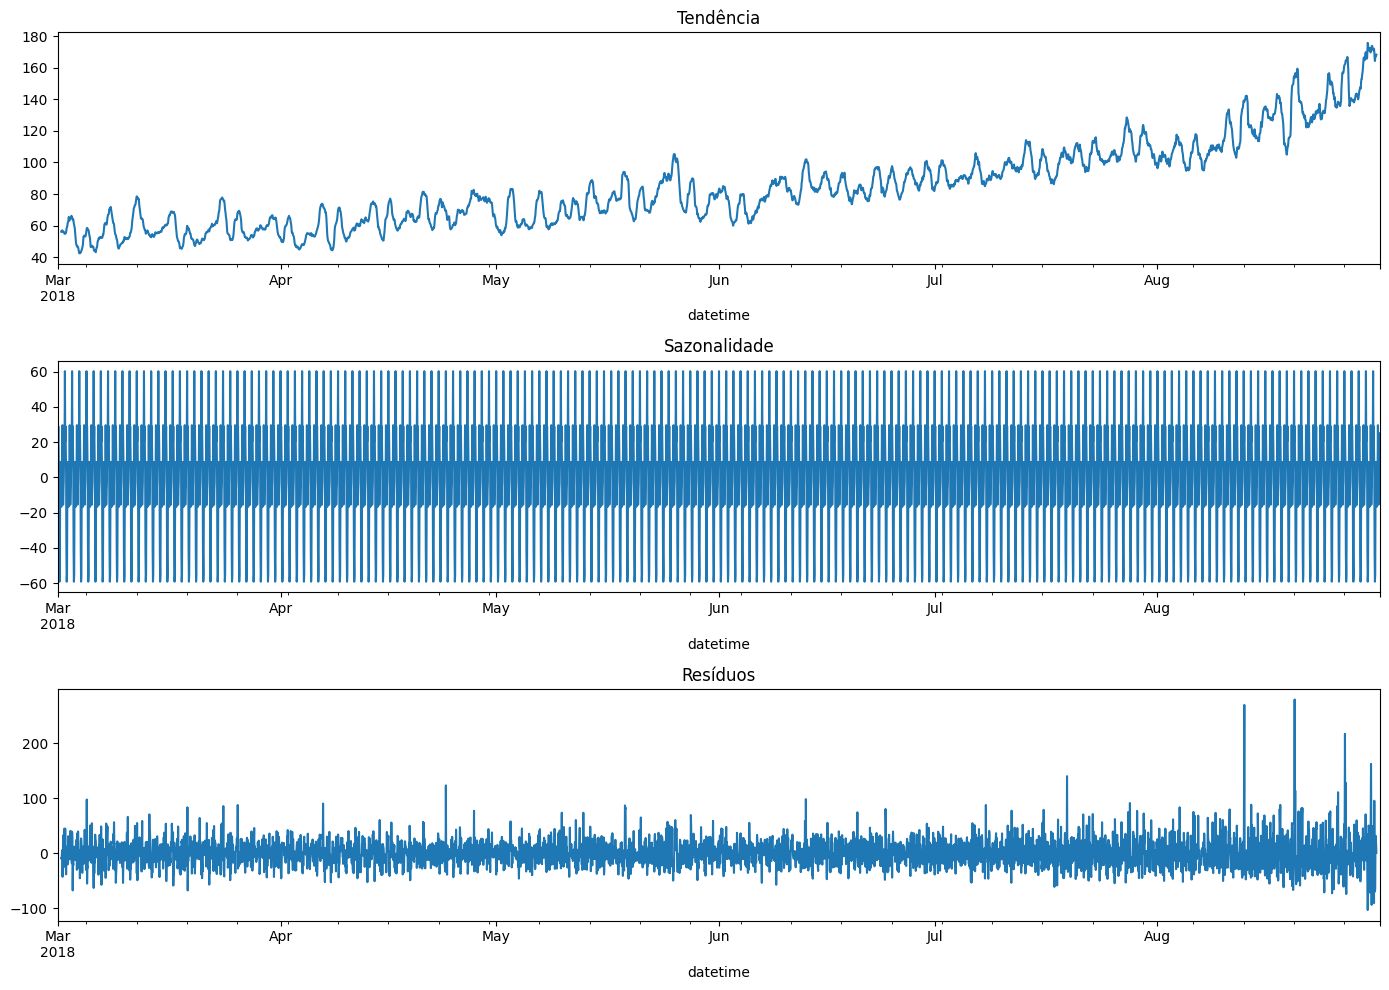

In [26]:
# Decompose the time series

decomposed = seasonal_decompose(
    data['num_orders'],
    period=24
)

plt.figure(figsize=(14, 10))

plt.subplot(311)
decomposed.trend.plot(ax=plt.gca())
plt.title('Trend')

plt.subplot(312)
decomposed.seasonal.plot(ax=plt.gca())
plt.title('Seasonality')

plt.subplot(313)
decomposed.resid.plot(ax=plt.gca())
plt.title('Residuals')

plt.tight_layout()
plt.show()

Time series decomposition shows an upward trend, a recurring daily seasonal pattern, and irregular residual fluctuations, including stronger spikes toward the end of the period.

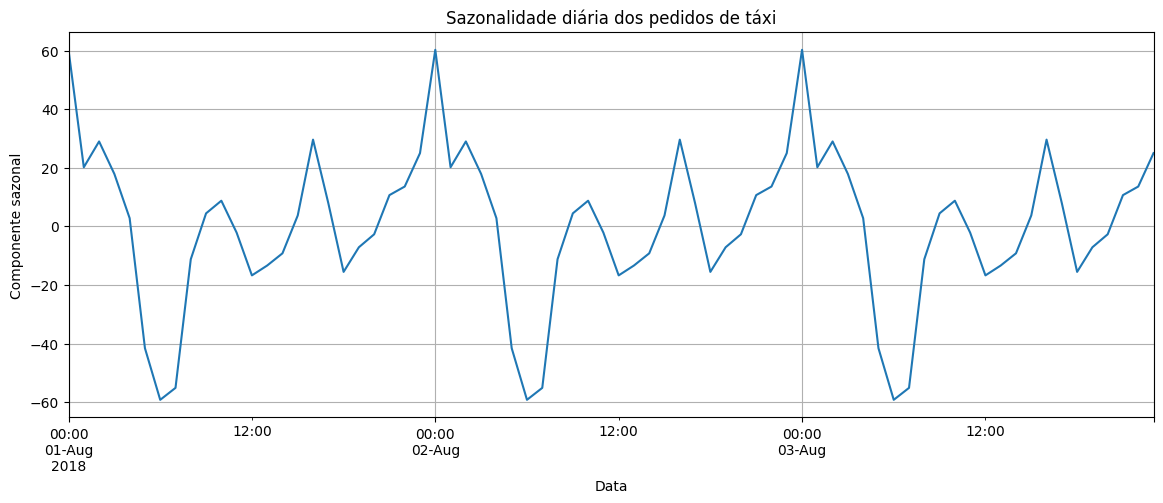

In [27]:
# Inspect daily seasonality

plt.figure(figsize=(14, 5))

decomposed.seasonal['2018-08-01':'2018-08-03'].plot()

plt.title('Daily seasonality in taxi orders')
plt.xlabel('Date')
plt.ylabel('Seasonal component')
plt.grid()
plt.show()

Taxi demand exhibits daily seasonality, with peaks near midnight and a pronounced decline between 5:00 and 7:00 a.m. Hour of day is therefore a relevant forecasting feature.

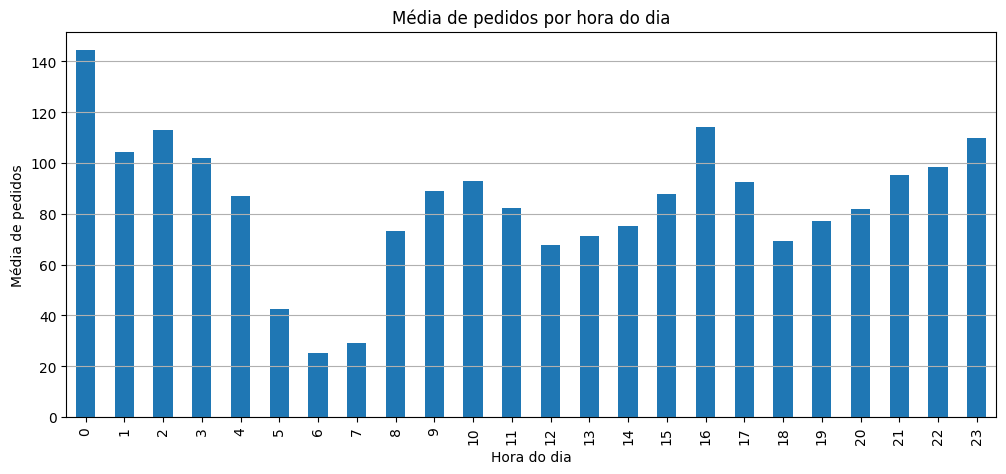

In [28]:
# Average orders by hour of day

hourly_mean = data.groupby(data.index.hour)['num_orders'].mean()

plt.figure(figsize=(12, 5))

hourly_mean.plot(kind='bar')

plt.title('Average orders by hour of day')
plt.xlabel('Hour of day')
plt.ylabel('Average orders')
plt.grid(axis='y')
plt.show()

Average demand is highest around midnight (approximately 145 orders per hour) and lowest around 6:00 a.m. (approximately 25 orders). A secondary peak appears around 4:00 p.m.

## 3. Feature Engineering and Model Training

In [29]:
# Create calendar, lag, and rolling-mean features

def make_features(data, max_lag, rolling_mean_size):
    data['hour'] = data.index.hour
    data['day'] = data.index.day
    data['dayofweek'] = data.index.dayofweek
    data['month'] = data.index.month

    for lag in range(1, max_lag + 1):
        data['lag_{}'.format(lag)] = data['num_orders'].shift(lag)

    data['rolling_mean'] = (
        data['num_orders'].shift(1).rolling(rolling_mean_size).mean()
    )

    return data


data_model = data[['num_orders']].copy()

data_model = make_features(
    data_model,
    max_lag=24,
    rolling_mean_size=24
)

print(data_model.head())
print()
print('Shape:', data_model.shape)
print()
print('Missing values:')
print(data_model.isna().sum())

                     num_orders  hour  day  dayofweek  month  lag_1  lag_2  \
datetime                                                                     
2018-03-01 00:00:00         124     0    1          3      3    NaN    NaN   
2018-03-01 01:00:00          85     1    1          3      3  124.0    NaN   
2018-03-01 02:00:00          71     2    1          3      3   85.0  124.0   
2018-03-01 03:00:00          66     3    1          3      3   71.0   85.0   
2018-03-01 04:00:00          43     4    1          3      3   66.0   71.0   

                     lag_3  lag_4  lag_5  ...  lag_16  lag_17  lag_18  lag_19  \
datetime                                  ...                                   
2018-03-01 00:00:00    NaN    NaN    NaN  ...     NaN     NaN     NaN     NaN   
2018-03-01 01:00:00    NaN    NaN    NaN  ...     NaN     NaN     NaN     NaN   
2018-03-01 02:00:00    NaN    NaN    NaN  ...     NaN     NaN     NaN     NaN   
2018-03-01 03:00:00  124.0    NaN    NaN  ...   

The forecasting dataset contains 29 engineered predictors, including calendar features, 24 hourly lags, and a 24-hour rolling mean. The rolling mean uses only previous observations (`shift(1)`) to avoid target leakage. Initial missing lag values are removed from the training and validation data.

In [30]:
# Chronological train, validation, and test split

train_valid, test = train_test_split(
    data_model,
    shuffle=False,
    test_size=0.1
)

train_valid = train_valid.dropna()

train, valid = train_test_split(
    train_valid,
    shuffle=False,
    test_size=0.2
)

print('Training:', train.shape)
print('Validation:', valid.shape)
print('Test:', test.shape)

print('\nPeriods:')
print('Training:', train.index.min(), 'até', train.index.max())
print('Validation:', valid.index.min(), 'até', valid.index.max())
print('Test:', test.index.min(), 'até', test.index.max())

Treinamento: (3160, 30)
Validação: (790, 30)
Teste: (442, 30)

Períodos:
Treinamento: 2018-03-02 00:00:00 até 2018-07-11 15:00:00
Validação: 2018-07-11 16:00:00 até 2018-08-13 13:00:00
Teste: 2018-08-13 14:00:00 até 2018-08-31 23:00:00


The data is split chronologically into 3,160 training, 790 validation, and 442 test observations. The last 10% is held out for final testing, while earlier observations are used for training and validation.

In [31]:
# Train the Linear Regression baseline

features_train = train.drop('num_orders', axis=1)
target_train = train['num_orders']

features_valid = valid.drop('num_orders', axis=1)
target_valid = valid['num_orders']

model_lr = LinearRegression()
model_lr.fit(features_train, target_train)

pred_valid_lr = model_lr.predict(features_valid)

rmse_lr = np.sqrt(
    mean_squared_error(target_valid, pred_valid_lr)
)

print('Linear Regression RMSE:', rmse_lr)

REQM Regressão Linear: 33.151986799972455


The Linear Regression baseline achieved a validation RMSE of approximately **33.15**.

In [32]:
# Tune the Random Forest model

best_rmse_rf = float('inf')
best_model_rf = None
best_params_rf = None

for n_estimators in [50, 100, 150]:
    for max_depth in [5, 10, 15]:

        model_rf = RandomForestRegressor(
            n_estimators=n_estimators,
            max_depth=max_depth,
            random_state=12345,
            n_jobs=-1
        )

        model_rf.fit(features_train, target_train)

        predictions = model_rf.predict(features_valid)

        rmse = np.sqrt(
            mean_squared_error(target_valid, predictions)
        )

        print(
            'Trees:', n_estimators,
            '| Max depth:', max_depth,
            '| RMSE:', rmse
        )

        if rmse < best_rmse_rf:
            best_rmse_rf = rmse
            best_model_rf = model_rf
            best_params_rf = (n_estimators, max_depth)

print('\nBest Random Forest RMSE:', best_rmse_rf)
print('Best parameters:', best_params_rf)

Árvores: 50 | Profundidade: 5 | REQM: 36.62458328258246
Árvores: 50 | Profundidade: 10 | REQM: 33.490055896253814
Árvores: 50 | Profundidade: 15 | REQM: 33.04746635535152
Árvores: 100 | Profundidade: 5 | REQM: 36.47249833316659
Árvores: 100 | Profundidade: 10 | REQM: 33.316506715106854
Árvores: 100 | Profundidade: 15 | REQM: 32.7888143601944
Árvores: 150 | Profundidade: 5 | REQM: 36.331875830899705
Árvores: 150 | Profundidade: 10 | REQM: 33.25528939352066
Árvores: 150 | Profundidade: 15 | REQM: 32.76574183164847

Melhor REQM Floresta Aleatória: 32.76574183164847
Melhores parâmetros: (150, 15)


In [33]:
# Tune the LightGBM model

from lightgbm import LGBMRegressor

best_rmse_lgbm = float('inf')
best_model_lgbm = None
best_params_lgbm = None

for n_estimators in [100, 200, 300]:
    for learning_rate in [0.05, 0.1]:

        model_lgbm = LGBMRegressor(
            n_estimators=n_estimators,
            learning_rate=learning_rate,
            max_depth=10,
            random_state=12345,
            verbosity=-1
        )

        model_lgbm.fit(features_train, target_train)

        predictions = model_lgbm.predict(features_valid)

        rmse = np.sqrt(
            mean_squared_error(target_valid, predictions)
        )

        print(
            'Trees:', n_estimators,
            '| Learning rate:', learning_rate,
            '| RMSE:', rmse
        )

        if rmse < best_rmse_lgbm:
            best_rmse_lgbm = rmse
            best_model_lgbm = model_lgbm
            best_params_lgbm = (n_estimators, learning_rate)

print('\nBest LightGBM RMSE:', best_rmse_lgbm)
print('Best parameters:', best_params_lgbm)

Árvores: 100 | Taxa de aprendizado: 0.05 | REQM: 31.95997516082936
Árvores: 100 | Taxa de aprendizado: 0.1 | REQM: 32.3071616300992
Árvores: 200 | Taxa de aprendizado: 0.05 | REQM: 31.991937013204005
Árvores: 200 | Taxa de aprendizado: 0.1 | REQM: 32.40621433516706
Árvores: 300 | Taxa de aprendizado: 0.05 | REQM: 32.027733620985614
Árvores: 300 | Taxa de aprendizado: 0.1 | REQM: 32.66711260377661

Melhor REQM LightGBM: 31.95997516082936
Melhores parâmetros: (100, 0.05)


LightGBM achieved its best validation RMSE of approximately **31.96**, using 100 estimators and a learning rate of 0.05.

In [34]:
# Compare validation performance

results = pd.DataFrame({
    'Modelo': [
        'Linear Regression',
        'Random Forest',
        'LightGBM'
    ],
    'Validation RMSE': [
        rmse_lr,
        best_rmse_rf,
        best_rmse_lgbm
    ]
})

results = results.sort_values('Validation RMSE')

print(results)

               Modelo  REQM Validação
2            LightGBM       31.959975
1  Floresta Aleatória       32.765742
0    Regressão Linear       33.151987


Among the evaluated models, **LightGBM** had the lowest validation RMSE (**31.96**), followed by **Random Forest** (**32.77**) and **Linear Regression** (**33.15**). LightGBM was selected for final evaluation.

## 4. Final Test Evaluation

In [35]:
# Fit the selected LightGBM model on training and validation data

from lightgbm import LGBMRegressor

features_train_valid = train_valid.drop('num_orders', axis=1)
target_train_valid = train_valid['num_orders']

final_model = LGBMRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=10,
    random_state=12345,
    verbosity=-1
)

final_model.fit(features_train_valid, target_train_valid)

print('Final training completed!')
print('Observations used:', len(features_train_valid))

Treinamento final concluído!
Registros utilizados: 3950


In [36]:
# Evaluate the model on the held-out test set

features_test = test.drop('num_orders', axis=1)
target_test = test['num_orders']

predictions_test = final_model.predict(features_test)

rmse_test = np.sqrt(
    mean_squared_error(target_test, predictions_test)
)

print('Test RMSE:', rmse_test)

if rmse_test <= 48:
    print('The model meets the RMSE target!')
else:
    print('The model does not meet the RMSE target.')

REQM no conjunto de teste: 41.723674031761526
O modelo atingiu a meta do projeto!


The selected LightGBM model achieved a test RMSE of approximately **41.72**, meeting the required threshold of **48** on held-out observations.

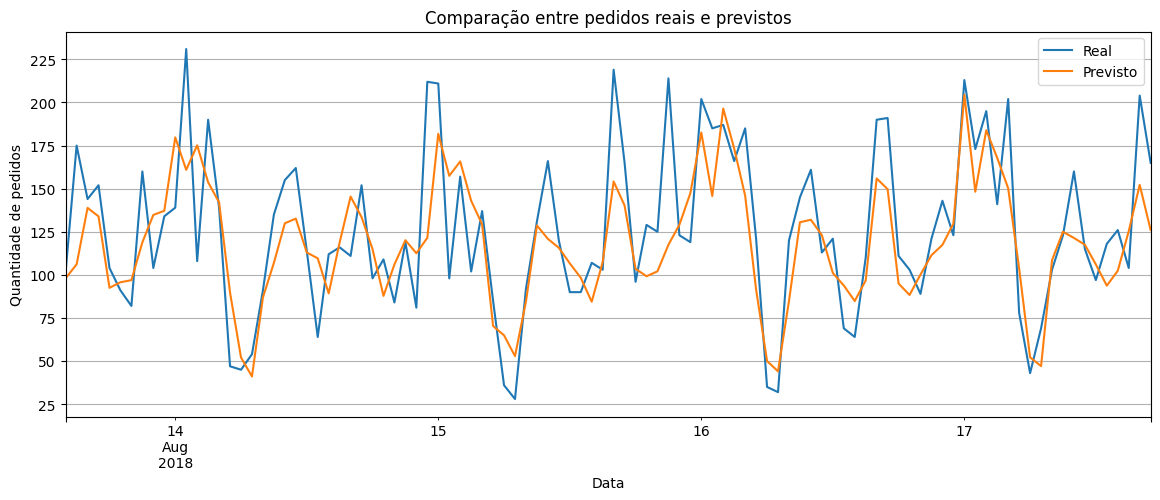

In [37]:
# Compare actual and predicted hourly orders

comparison = pd.DataFrame({
    'Actual': target_test,
    'Predicted': predictions_test
}, index=target_test.index)

comparison.head(100).plot(figsize=(14, 5))

plt.title('Actual vs. predicted taxi orders')
plt.xlabel('Date')
plt.ylabel('Number of orders')
plt.legend()
plt.grid()
plt.show()

The prediction plot indicates that the model follows the main changes in demand, although some individual peaks are not captured precisely.

## 5. Conclusion

This project forecasted hourly airport taxi orders using historical demand, calendar features, lagged observations, and a rolling mean. Linear Regression, Random Forest, and LightGBM were compared on a chronological validation split.

**LightGBM achieved the lowest validation RMSE (31.96)** and a **final test RMSE of 41.72**, satisfying the target of 48 or lower. These forecasts could help Sweet Lift Taxi plan driver availability during periods of higher demand.

**Limitations:** The model does not explicitly incorporate external signals such as flight schedules, weather, or special events. Performance should be monitored if demand patterns change.